In [38]:
# Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import (
    kruskal,
    pearsonr,
    spearmanr
)

import warnings

warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


**2. ASK + PREPARE**

**1.Set up**

**Upload and Load the Original Dataset**

In [39]:

# Upload and Load Dataset

from google.colab import files

# Upload original CSV file
uploaded = files.upload()

# Get uploaded file name
file_name = next(iter(uploaded))

# Read CSV file
df = pd.read_csv(file_name)

# Display basic information
print("File uploaded successfully!")
print("File Name:", file_name)
print("Dataset Shape:", df.shape)

# Display first 5 rows
display(df.head())


Saving Untitled spreadsheet - Table data.csv to Untitled spreadsheet - Table data (2).csv
File uploaded successfully!
File Name: Untitled spreadsheet - Table data (2).csv
Dataset Shape: (241, 16)


,Category,Video Duration,Video title,Video publish time,Duration,New viewers,Stayed to watch (%),Unique viewers,Average view duration,Engaged views,Average percentage viewed (%),Casual viewers,Regular viewers,Average views per viewer,Views,Subscribers
0,NaN,Total,NaN,NaN,NaN,0.00,40.64,0.00,0:00:19,112856,65.39,0.00,0.00,0.00,236253,343
1,Cricket,ImzR9EkzLJo,🇮🇳 Asia Cup 2025 Final Drama! Surya ने Trophy लेने से किया इंकार 🔥🏆 #AsiaCup2025 #INDvsPAK,"Sep 29, 2025",43.00,NaN,18.19,NaN,0:00:24,409,57.19,NaN,NaN,NaN,2276,0
2,Politics,vglwfC_SqAE,2 Saal Baad Manipur ke CM N Biren Singh ne Diya Istifa #ManipurViolence #NBirenSinghResigns,"Feb 12, 2025",23.00,NaN,36.00,NaN,0:00:20,10,90.29,NaN,NaN,NaN,23,0
3,Politics,-PAkuh1_KhM,"Budget 2025 DeepSeek AI, Startup Fund और IIT-Medical Seats का बड़ा ऐलान!#Budget2025 #DeepSeekAI","Feb 1, 2025",19.00,NaN,34.13,NaN,0:00:13,514,72.84,NaN,NaN,NaN,519,1
4,Movie Review,BC0vvL6M0tc,Sitare Zameen Par ne jeeta dil! ❤️#SitareZameenPar #AamirKhanMovie,"Jun 22, 2025",27.00,NaN,27.43,NaN,0:00:14,341,52.46,NaN,NaN,NaN,1292,0


**Understand Dataset Structure**

In [40]:

# Dataset Structure Analysis

# 1. Dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# 2. Column names
print("\nColumn Names:")
for column in df.columns:
    print("-", column)

# 3. Dataset information
print("\nDataset Information:")
df.info()

# 4. Statistical summary
print("\nNumerical Summary:")
display(df.describe().T)

# 5. Sample records
print("\nRandom 5 Records:")
display(df.sample(min(5, len(df)), random_state=42))


Number of Rows: 241
Number of Columns: 16

Column Names:
- Category
- Video Duration
- Video title
- Video publish time
- Duration
- New viewers
- Stayed to watch (%)
- Unique viewers
- Average view duration
- Engaged views
- Average percentage viewed (%)
- Casual viewers
- Regular viewers
- Average views per viewer
- Views
- Subscribers

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Category                       240 non-null    object 
 1   Video Duration                 241 non-null    object 
 2   Video title                    240 non-null    object 
 3   Video publish time             239 non-null    object 
 4   Duration                       240 non-null    float64
 5   New viewers                    1 non-null      float64
 6   Stayed to watch (%)            241 non-null    f

,count,mean,std,min,25%,50%,75%,max
Duration,240.00,29.53,7.97,18.00,23.00,28.00,34.00,64.00
New viewers,1.00,0.00,NaN,0.00,0.00,0.00,0.00,0.00
Stayed to watch (%),241.00,39.58,13.55,0.00,30.66,38.96,48.57,74.58
Unique viewers,1.00,0.00,NaN,0.00,0.00,0.00,0.00,0.00
Engaged views,241.00,932.47,7252.84,0.00,234.00,429.00,527.00,112856.00
Average percentage viewed (%),240.00,65.50,15.27,41.08,55.58,64.23,71.39,161.26
Casual viewers,1.00,0.00,NaN,0.00,0.00,0.00,0.00,0.00
Regular viewers,1.00,0.00,NaN,0.00,0.00,0.00,0.00,0.00
Average views per viewer,1.00,0.00,NaN,0.00,0.00,0.00,0.00,0.00
Views,241.00,1949.76,15183.88,2.00,416.00,688.00,1338.00,236253.00



Random 5 Records:


,Category,Video Duration,Video title,Video publish time,Duration,New viewers,Stayed to watch (%),Unique viewers,Average view duration,Engaged views,Average percentage viewed (%),Casual viewers,Regular viewers,Average views per viewer,Views,Subscribers
24,Cricket,GzuDFuz5sjs,Lucknow Super Giants: ₹27 Crore Ka Smart Move Ya Galti? #LSG #IPL2025,"Mar 20, 2025",24.00,NaN,18.35,NaN,0:00:13,29,56.16,NaN,NaN,NaN,39,0
6,Cricket,ttQBWinoSkU,IPL 2025 की कौन-सी टीम है ट्रॉफी की सबसे मजबूत दावेदार ? #IPL2025 #CricketPrediction,"May 3, 2025",29.00,NaN,41.70,NaN,0:00:15,465,55.16,NaN,NaN,NaN,1148,4
222,Movie Review,f9dBqBbOFfU,"Akshay Kumar Ka Zabardast Comeback | Skyforce, Kesari 2 Se Housefull 5 Tak #AkshayKumar #Kesari2","Apr 30, 2025",23.00,NaN,32.16,NaN,0:00:12,431,55.62,NaN,NaN,NaN,1355,2
208,Cricket,cWKFiuwuq7M,Mumbai Indians Ka Comeback? Trophy Ki Daur Me Wapas! #MumbaiIndians #IPL2025,"Apr 18, 2025",27.00,NaN,32.95,NaN,0:00:14,401,52.83,NaN,NaN,NaN,1196,0
236,Cricket,vP5CdRcTCow,IPL 2025 ke Uncapped Ballebaazon ne machaya hungama | Ayush Matre ki class dikhi #IPL2025,"May 5, 2025",30.00,NaN,29.56,NaN,0:00:17,407,59.63,NaN,NaN,NaN,1354,0


**Separate Total Row from Individual Videos**

In [41]:

# Separate Aggregate and Video-Level Data

# Identify aggregate Total row
total_row = df[
    df["Video Duration"].astype(str).str.strip().str.lower() == "total"
].copy()

# Keep individual video records
videos = df[
    df["Video Duration"].astype(str).str.strip().str.lower() != "total"
].copy()

# Display results
print("Original Dataset Rows:", len(df))
print("Aggregate Rows:", len(total_row))
print("Individual Video Rows:", len(videos))

print("\nAggregate Total Row:")
display(total_row)

print("\nIndividual Video Sample:")
display(videos.head())


Original Dataset Rows: 241
Aggregate Rows: 1
Individual Video Rows: 240

Aggregate Total Row:


,Category,Video Duration,Video title,Video publish time,Duration,New viewers,Stayed to watch (%),Unique viewers,Average view duration,Engaged views,Average percentage viewed (%),Casual viewers,Regular viewers,Average views per viewer,Views,Subscribers
0,NaN,Total,NaN,NaN,NaN,0.00,40.64,0.00,0:00:19,112856,65.39,0.00,0.00,0.00,236253,343



Individual Video Sample:


,Category,Video Duration,Video title,Video publish time,Duration,New viewers,Stayed to watch (%),Unique viewers,Average view duration,Engaged views,Average percentage viewed (%),Casual viewers,Regular viewers,Average views per viewer,Views,Subscribers
1,Cricket,ImzR9EkzLJo,🇮🇳 Asia Cup 2025 Final Drama! Surya ने Trophy लेने से किया इंकार 🔥🏆 #AsiaCup2025 #INDvsPAK,"Sep 29, 2025",43.00,NaN,18.19,NaN,0:00:24,409,57.19,NaN,NaN,NaN,2276,0
2,Politics,vglwfC_SqAE,2 Saal Baad Manipur ke CM N Biren Singh ne Diya Istifa #ManipurViolence #NBirenSinghResigns,"Feb 12, 2025",23.00,NaN,36.00,NaN,0:00:20,10,90.29,NaN,NaN,NaN,23,0
3,Politics,-PAkuh1_KhM,"Budget 2025 DeepSeek AI, Startup Fund और IIT-Medical Seats का बड़ा ऐलान!#Budget2025 #DeepSeekAI","Feb 1, 2025",19.00,NaN,34.13,NaN,0:00:13,514,72.84,NaN,NaN,NaN,519,1
4,Movie Review,BC0vvL6M0tc,Sitare Zameen Par ne jeeta dil! ❤️#SitareZameenPar #AamirKhanMovie,"Jun 22, 2025",27.00,NaN,27.43,NaN,0:00:14,341,52.46,NaN,NaN,NaN,1292,0
5,Cricket,B4v_B3mA1dM,IPL 2025 Ka Sabse Safal Kaptan Kaun? | Shreyas Iyer Shines #IPL2025 #ShreyasIyer,"Apr 4, 2025",25.00,NaN,36.35,NaN,0:00:15,426,60.26,NaN,NaN,NaN,1187,0


**Define the Business Problem**

In [42]:

# Define Business Objective

project_title = "YouTube Content Portfolio Intelligence & Optimization"

business_problem = """
A YouTube channel has limited content production resources.
The channel publishes videos across multiple categories.

The objective is to identify:
1. Which categories generate stronger viewership?
2. Which categories attract better audience engagement?
3. Which categories receive more content effort than their
   contribution to total views?
4. Which categories show consistent performance?
5. How can the channel make more informed content decisions?
"""

analysis_scope = {
    "Unit of Analysis": "Individual YouTube videos",
    "Segmentation": "Content Category",
    "Primary Metric": "Views",
    "Engagement Metrics": [
        "Engaged views",
        "Stayed to watch (%)",
        "Average percentage viewed (%)"
    ],
    "Approach": "Exploratory and Statistical Analysis",
    "Machine Learning": "Not included"
}

print("PROJECT:", project_title)
print("\nBUSINESS PROBLEM:")
print(business_problem)

print("ANALYSIS SCOPE:")
display(pd.Series(analysis_scope))


PROJECT: YouTube Content Portfolio Intelligence & Optimization

BUSINESS PROBLEM:

A YouTube channel has limited content production resources.
The channel publishes videos across multiple categories.

The objective is to identify:
1. Which categories generate stronger viewership?
2. Which categories attract better audience engagement?
3. Which categories receive more content effort than their
   contribution to total views?
4. Which categories show consistent performance?
5. How can the channel make more informed content decisions?

ANALYSIS SCOPE:


,0
Unit of Analysis,Individual YouTube videos
Segmentation,Content Category
Primary Metric,Views
Engagement Metrics,"[Engaged views, Stayed to watch (%), Average percentage viewed (%)]"
Approach,Exploratory and Statistical Analysis
Machine Learning,Not included


**3.PROCESS**

**Data Quality Audit**

In [43]:

# Data Quality Audit

# 1. Missing values
missing_values = videos.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(videos) * 100
    ).round(2)
})

print("MISSING VALUE REPORT")
display(
    missing_summary[
        missing_summary["Missing Values"] > 0
    ].sort_values(
        by="Missing Percentage",
        ascending=False
    )
)

# 2. Duplicate records
duplicate_rows = videos.duplicated().sum()

print("\nDuplicate Rows:", duplicate_rows)

# 3. Unique values in important columns
print("\nUNIQUE CATEGORY VALUES:")
print(videos["Category"].value_counts(dropna=False))

# 4. Dataset quality overview
print("\nDATA QUALITY OVERVIEW")
print("Total Video Records:", len(videos))
print("Total Missing Cells:", videos.isnull().sum().sum())
print("Total Duplicate Rows:", duplicate_rows)
print("Total Columns:", videos.shape[1])


MISSING VALUE REPORT


,Missing Values,Missing Percentage
New viewers,240,100.00
Unique viewers,240,100.00
Regular viewers,240,100.00
Casual viewers,240,100.00
Average views per viewer,240,100.00
Video publish time,1,0.42
Average view duration,1,0.42
Average percentage viewed (%),1,0.42



Duplicate Rows: 0

UNIQUE CATEGORY VALUES:
Category
Cricket         105
Movie Review     46
Politics         36
Geopolitics      35
Pop-Culture      18
Name: count, dtype: int64

DATA QUALITY OVERVIEW
Total Video Records: 240
Total Missing Cells: 1203
Total Duplicate Rows: 0
Total Columns: 16


**Convert Columns into Correct Data Types**

In [45]:
# Data Type Conversion

# Columns that should contain numerical values
numeric_columns = [
    "Duration",
    "New viewers",
    "Stayed to watch (%)",
    "Unique viewers",
    "Average view duration",
    "Engaged views",
    "Average percentage viewed (%)",
    "Casual viewers",
    "Regular viewers",
    "Average views per viewer",
    "Views",
    "Subscribers"
]

# Convert numerical columns
for column in numeric_columns:
    videos[column] = pd.to_numeric(
        videos[column],
        errors="coerce"
    )

# Convert publishing date
videos["Video publish time"] = pd.to_datetime(
    videos["Video publish time"],
    errors="coerce"
)

# Display updated data types
print("UPDATED DATA TYPES:")
display(videos.dtypes.to_frame(name="Data Type"))

# Display sample records
print("\nUPDATED DATA SAMPLE:")
display(videos.head())

UPDATED DATA TYPES:


,Data Type
Category,object
Video Duration,object
Video title,object
Video publish time,datetime64[ns]
Duration,float64
New viewers,float64
Stayed to watch (%),float64
Unique viewers,float64
Average view duration,float64
Engaged views,int64



UPDATED DATA SAMPLE:


,Category,Video Duration,Video title,Video publish time,Duration,New viewers,Stayed to watch (%),Unique viewers,Average view duration,Engaged views,Average percentage viewed (%),Casual viewers,Regular viewers,Average views per viewer,Views,Subscribers
1,Cricket,ImzR9EkzLJo,🇮🇳 Asia Cup 2025 Final Drama! Surya ने Trophy लेने से किया इंकार 🔥🏆 #AsiaCup2025 #INDvsPAK,2025-09-29,43.00,NaN,18.19,NaN,NaN,409,57.19,NaN,NaN,NaN,2276,0
2,Politics,vglwfC_SqAE,2 Saal Baad Manipur ke CM N Biren Singh ne Diya Istifa #ManipurViolence #NBirenSinghResigns,2025-02-12,23.00,NaN,36.00,NaN,NaN,10,90.29,NaN,NaN,NaN,23,0
3,Politics,-PAkuh1_KhM,"Budget 2025 DeepSeek AI, Startup Fund और IIT-Medical Seats का बड़ा ऐलान!#Budget2025 #DeepSeekAI",2025-02-01,19.00,NaN,34.13,NaN,NaN,514,72.84,NaN,NaN,NaN,519,1
4,Movie Review,BC0vvL6M0tc,Sitare Zameen Par ne jeeta dil! ❤️#SitareZameenPar #AamirKhanMovie,2025-06-22,27.00,NaN,27.43,NaN,NaN,341,52.46,NaN,NaN,NaN,1292,0
5,Cricket,B4v_B3mA1dM,IPL 2025 Ka Sabse Safal Kaptan Kaun? | Shreyas Iyer Shines #IPL2025 #ShreyasIyer,2025-04-04,25.00,NaN,36.35,NaN,NaN,426,60.26,NaN,NaN,NaN,1187,0


**Standardize Column Names**

In [46]:

# Standardize Column Names

# Create a consistent column naming system
column_mapping = {
    "Category": "category",
    "Video Duration": "video_id",
    "Video title": "video_title",
    "Video publish time": "publish_time",
    "Duration (seconds)": "duration_seconds",
    "New viewers": "new_viewers",
    "Stayed to watch (%)": "stayed_to_watch_pct",
    "Unique viewers": "unique_viewers",
    "Average view duration": "average_view_duration",
    "Engaged views": "engaged_views",
    "Average percentage viewed (%)": "average_percentage_viewed_pct",
    "Casual viewers": "casual_viewers",
    "Regular viewers": "regular_viewers",
    "Average views per viewer": "average_views_per_viewer",
    "Views": "views",
    "Subscribers": "subscribers"
}

# Rename columns
videos.rename(columns=column_mapping, inplace=True)

# Verify standardized column names
print("STANDARDIZED COLUMN NAMES:")
print(videos.columns.tolist())

# Check updated structure
print("\nUPDATED DATASET SHAPE:", videos.shape)

display(videos.head())


STANDARDIZED COLUMN NAMES:
['category', 'video_id', 'video_title', 'publish_time', 'Duration', 'new_viewers', 'stayed_to_watch_pct', 'unique_viewers', 'average_view_duration', 'engaged_views', 'average_percentage_viewed_pct', 'casual_viewers', 'regular_viewers', 'average_views_per_viewer', 'views', 'subscribers']

UPDATED DATASET SHAPE: (240, 16)


,category,video_id,video_title,publish_time,Duration,new_viewers,stayed_to_watch_pct,unique_viewers,average_view_duration,engaged_views,average_percentage_viewed_pct,casual_viewers,regular_viewers,average_views_per_viewer,views,subscribers
1,Cricket,ImzR9EkzLJo,🇮🇳 Asia Cup 2025 Final Drama! Surya ने Trophy लेने से किया इंकार 🔥🏆 #AsiaCup2025 #INDvsPAK,2025-09-29,43.00,NaN,18.19,NaN,NaN,409,57.19,NaN,NaN,NaN,2276,0
2,Politics,vglwfC_SqAE,2 Saal Baad Manipur ke CM N Biren Singh ne Diya Istifa #ManipurViolence #NBirenSinghResigns,2025-02-12,23.00,NaN,36.00,NaN,NaN,10,90.29,NaN,NaN,NaN,23,0
3,Politics,-PAkuh1_KhM,"Budget 2025 DeepSeek AI, Startup Fund और IIT-Medical Seats का बड़ा ऐलान!#Budget2025 #DeepSeekAI",2025-02-01,19.00,NaN,34.13,NaN,NaN,514,72.84,NaN,NaN,NaN,519,1
4,Movie Review,BC0vvL6M0tc,Sitare Zameen Par ne jeeta dil! ❤️#SitareZameenPar #AamirKhanMovie,2025-06-22,27.00,NaN,27.43,NaN,NaN,341,52.46,NaN,NaN,NaN,1292,0
5,Cricket,B4v_B3mA1dM,IPL 2025 Ka Sabse Safal Kaptan Kaun? | Shreyas Iyer Shines #IPL2025 #ShreyasIyer,2025-04-04,25.00,NaN,36.35,NaN,NaN,426,60.26,NaN,NaN,NaN,1187,0


**Validate Data Quality**

In [48]:

# Data Validation

# 1. Check missing values after conversion
print("MISSING VALUES:")
display(
    videos.isnull().sum()
    .to_frame(name="Missing Count")
    .query("`Missing Count` > 0")
)

# 2. Check duplicate video IDs
print("\nDUPLICATE VIDEO IDs:")
print(videos["video_id"].duplicated().sum())

# 3. Check negative values
non_negative_columns = [
    "Duration",
    "new_viewers",
    "unique_viewers",
    "engaged_views",
    "casual_viewers",
    "regular_viewers",
    "views",
    "subscribers"
]

print("\nNEGATIVE VALUE CHECK:")
for column in non_negative_columns:
    negative_count = (videos[column] < 0).sum()
    print(f"{column}: {negative_count}")

# 4. Check zero or invalid duration
print("\nINVALID DURATION:")
print((videos["Duration"] <= 0).sum())

# 5. Check percentage ranges
percentage_columns = [
    "stayed_to_watch_pct",
    "average_percentage_viewed_pct"
]

print("\nPERCENTAGE VALIDATION:")
for column in percentage_columns:
    invalid_count = (
        (videos[column] < 0) |
        (videos[column] > 100)
    ).sum()

    print(f"{column}: {invalid_count} values outside 0–100")

# 6. Check category and title missing values
print("\nCRITICAL TEXT FIELD CHECK:")
print("Missing Categories:", videos["category"].isnull().sum())
print("Missing Titles:", videos["video_title"].isnull().sum())


MISSING VALUES:


,Missing Count
publish_time,1
new_viewers,240
unique_viewers,240
average_view_duration,240
average_percentage_viewed_pct,1
casual_viewers,240
regular_viewers,240
average_views_per_viewer,240



DUPLICATE VIDEO IDs:
0

NEGATIVE VALUE CHECK:
Duration: 0
new_viewers: 0
unique_viewers: 0
engaged_views: 0
casual_viewers: 0
regular_viewers: 0
views: 0
subscribers: 0

INVALID DURATION:
0

PERCENTAGE VALIDATION:
stayed_to_watch_pct: 0 values outside 0–100
average_percentage_viewed_pct: 5 values outside 0–100

CRITICAL TEXT FIELD CHECK:
Missing Categories: 0
Missing Titles: 0


**Detect Performance Outliers**

In [49]:

# Outlier Detection Using IQR

# Select views column and remove missing values
views_data = videos["views"].dropna()

# Calculate quartiles
Q1 = views_data.quantile(0.25)
Q3 = views_data.quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

# Identify outliers
outlier_mask = (
    (videos["views"] < lower_limit) |
    (videos["views"] > upper_limit)
)

outliers = videos.loc[outlier_mask].copy()

# Display results
print("OUTLIER DETECTION REPORT")
print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Limit:", round(lower_limit, 2))
print("Upper Limit:", round(upper_limit, 2))

print("\nTotal Videos:", len(videos))
print("Detected Outliers:", len(outliers))
print("Outlier Percentage:", round(len(outliers) / len(videos) * 100, 2), "%")

print("\nTOP 10 OUTLIER VIDEOS:")
display(
    outliers[
        ["category", "video_title", "views", "engaged_views"]
    ].sort_values(
        by="views",
        ascending=False
    ).head(10)
)


OUTLIER DETECTION REPORT
Q1: 415.0
Q3: 1338.0
IQR: 923.0
Lower Limit: -969.5
Upper Limit: 2722.5

Total Videos: 240
Detected Outliers: 15
Outlier Percentage: 6.25 %

TOP 10 OUTLIER VIDEOS:


,category,video_title,views,engaged_views
136,Movie Review,"Kesari Chapter 2: Jallianwala Bagh Massacre | Akshay Kumar, R. Madhavan #Kesari2 #AkshayKumar",6888,3418
21,Movie Review,Sunny vs Akshay 2.0! Kiski film karegi dhamaka? #SunnyDeol #KesariChapter2 #jaatmovie,5075,2823
88,Movie Review,Jaat ne 8 din baad bhi dikhaya dum – Kesari 2 opening me peeche!#JaatVsKesari2 #BoxOfficeIndia,3800,1924
217,Movie Review,Saiyara Movie Review: Hit hai ya Hype? Mohit Suri Magic!#SaiyaraReview #MohitSuriFilm,3768,2699
200,Movie Review,"Kesari 2 box office par chhayi, Sunny Deol ne ki Jaat 2 ki announcement! #Kesari2 #Jaat2",3585,1877
55,Geopolitics,"""Indian YouTuber Jyoti Malhotra par ISI ke liye jasoosi ka aarop!"" #JyotiMalhotra #ISIJasoos",3436,1758
197,Movie Review,Kesari 2 vs Jaat! Bhootni Ne Release Date Badli! #SunnyDeol #Kesari2,3404,1870
164,Pop-Culture,Colonel Sofia aur Wing Commander Vyomika Ke Sath Ekta ka jawab Operation Sindoor ! #BharatKeHero,3356,1379
125,Movie Review,"Saiyara ने मचाया धमाल | Housefull 5, Raid 2, Sitare Zameen Par सब पीछे #SaiyaraSuccess#BoxOffice...",3340,624
220,Cricket,Shubman Gill Test Captain | Karun Nair Ki 8 Saal Baad Wapsi! #INDvsENG #GillCaptaincy,2958,430


**Extract Publishing Date Features**

In [50]:

# Publishing Date Feature Engineering

# Extract year
videos["publish_year"] = videos["publish_time"].dt.year

# Extract month number
videos["publish_month"] = videos["publish_time"].dt.month

# Extract month name
videos["publish_month_name"] = (
    videos["publish_time"].dt.month_name()
)

# Extract day of week
videos["publish_day"] = (
    videos["publish_time"].dt.day_name()
)

# Extract day number
videos["publish_day_number"] = (
    videos["publish_time"].dt.day
)

# Extract quarter
videos["publish_quarter"] = (
    videos["publish_time"].dt.quarter
)

# Display new features
date_features = [
    "video_title",
    "publish_time",
    "publish_year",
    "publish_month",
    "publish_month_name",
    "publish_day",
    "publish_quarter"
]

print("PUBLISHING DATE FEATURES:")
display(videos[date_features].head(10))

# Check missing publishing dates
print(
    "\nMissing Publishing Dates:",
    videos["publish_time"].isna().sum()
)


PUBLISHING DATE FEATURES:


,video_title,publish_time,publish_year,publish_month,publish_month_name,publish_day,publish_quarter
1,🇮🇳 Asia Cup 2025 Final Drama! Surya ने Trophy लेने से किया इंकार 🔥🏆 #AsiaCup2025 #INDvsPAK,2025-09-29,2025.00,9.00,September,Monday,3.00
2,2 Saal Baad Manipur ke CM N Biren Singh ne Diya Istifa #ManipurViolence #NBirenSinghResigns,2025-02-12,2025.00,2.00,February,Wednesday,1.00
3,"Budget 2025 DeepSeek AI, Startup Fund और IIT-Medical Seats का बड़ा ऐलान!#Budget2025 #DeepSeekAI",2025-02-01,2025.00,2.00,February,Saturday,1.00
4,Sitare Zameen Par ne jeeta dil! ❤️#SitareZameenPar #AamirKhanMovie,2025-06-22,2025.00,6.00,June,Sunday,2.00
5,IPL 2025 Ka Sabse Safal Kaptan Kaun? | Shreyas Iyer Shines #IPL2025 #ShreyasIyer,2025-04-04,2025.00,4.00,April,Friday,2.00
6,IPL 2025 की कौन-सी टीम है ट्रॉफी की सबसे मजबूत दावेदार ? #IPL2025 #CricketPrediction,2025-05-03,2025.00,5.00,May,Saturday,2.00
7,Iyer & Kishan ki Comeback | BCCI Contract 2025 Se Bahar Hue Ye Players #IndianCricket #CricketNews,2025-04-21,2025.00,4.00,April,Monday,2.00
8,MI vs RCB | Bumrah Ka Comeback | Kya Mumbai Karegi Dhamaka #MIvsRCB #BumrahComeback,2025-04-07,2025.00,4.00,April,Monday,2.00
9,Sikandar Box Office: Blockbuster Ya Disappointment? #SalmanKhan #SikandarMovie,2025-03-31,2025.00,3.00,March,Monday,1.00
10,Israel-Iran War: Ek Desh Vs 6 Dushman | Tech aur Intelligence ka Kamaal! #WorldWarAlert,2025-06-16,2025.00,6.00,June,Monday,2.00



Missing Publishing Dates: 1


**Create Video Duration Groups**

In [52]:

# Video Duration Feature Engineering

# Convert duration into minutes
videos["duration_minutes"] = (
    videos["Duration"] / 60
)

# Create duration groups
duration_bins = [0, 15, 30, 45, 60, float("inf")]

duration_labels = [
    "0-15 sec",
    "15-30 sec",
    "30-45 sec",
    "45-60 sec",
    "60+ sec"
]

videos["duration_group"] = pd.cut(
    videos["Duration"],
    bins=duration_bins,
    labels=duration_labels,
    right=True
)

# Display duration distribution
print("VIDEO DURATION GROUP DISTRIBUTION:")

duration_distribution = (
    videos["duration_group"]
    .value_counts(sort=False)
    .to_frame(name="Video Count")
)

duration_distribution["Percentage"] = (
    duration_distribution["Video Count"] /
    len(videos) * 100
).round(2)

display(duration_distribution)

# Display sample records
print("\nDURATION FEATURE SAMPLE:")
display(
    videos[
        [
            "video_title",
            "Duration",
            "duration_minutes",
            "duration_group"
        ]
    ].head(10)
)


VIDEO DURATION GROUP DISTRIBUTION:


,Video Count,Percentage
duration_group,,
0-15 sec,0,0.00
15-30 sec,154,64.17
30-45 sec,75,31.25
45-60 sec,10,4.17
60+ sec,1,0.42



DURATION FEATURE SAMPLE:


,video_title,Duration,duration_minutes,duration_group
1,🇮🇳 Asia Cup 2025 Final Drama! Surya ने Trophy लेने से किया इंकार 🔥🏆 #AsiaCup2025 #INDvsPAK,43.00,0.72,30-45 sec
2,2 Saal Baad Manipur ke CM N Biren Singh ne Diya Istifa #ManipurViolence #NBirenSinghResigns,23.00,0.38,15-30 sec
3,"Budget 2025 DeepSeek AI, Startup Fund और IIT-Medical Seats का बड़ा ऐलान!#Budget2025 #DeepSeekAI",19.00,0.32,15-30 sec
4,Sitare Zameen Par ne jeeta dil! ❤️#SitareZameenPar #AamirKhanMovie,27.00,0.45,15-30 sec
5,IPL 2025 Ka Sabse Safal Kaptan Kaun? | Shreyas Iyer Shines #IPL2025 #ShreyasIyer,25.00,0.42,15-30 sec
6,IPL 2025 की कौन-सी टीम है ट्रॉफी की सबसे मजबूत दावेदार ? #IPL2025 #CricketPrediction,29.00,0.48,15-30 sec
7,Iyer & Kishan ki Comeback | BCCI Contract 2025 Se Bahar Hue Ye Players #IndianCricket #CricketNews,30.00,0.50,15-30 sec
8,MI vs RCB | Bumrah Ka Comeback | Kya Mumbai Karegi Dhamaka #MIvsRCB #BumrahComeback,25.00,0.42,15-30 sec
9,Sikandar Box Office: Blockbuster Ya Disappointment? #SalmanKhan #SikandarMovie,19.00,0.32,15-30 sec
10,Israel-Iran War: Ek Desh Vs 6 Dushman | Tech aur Intelligence ka Kamaal! #WorldWarAlert,38.00,0.63,30-45 sec


**Create Video-Level Performance Metrics**

In [54]:
# Video-Level Performance Metrics

# 1. Engagement views as a percentage of total views
videos["engaged_view_share_pct"] = np.where(
    videos["views"] > 0,
    (videos["engaged_views"] / videos["views"]) * 100,
    np.nan
)

# 2. Subscriber conversion per 1,000 views
videos["subscribers_per_1000_views"] = np.where(
    videos["views"] > 0,
    (videos["subscribers"] / videos["views"]) * 1000,
    np.nan
)

# 3. Views per second of video duration
videos["views_per_second_duration"] = np.where(
    videos["Duration"] > 0,
    videos["views"] / videos["Duration"],
    np.nan
)

# 4. Flag videos with missing core performance metrics
videos["performance_data_complete"] = (
    videos[
        [
            "views",
            "engaged_views",
            "subscribers",
            "stayed_to_watch_pct",
            "average_percentage_viewed_pct"
        ]
    ].notna().all(axis=1)
)

# Display new metrics
performance_columns = [
    "category",
    "video_title",
    "views",
    "engaged_views",
    "subscribers",
    "engaged_view_share_pct",
    "subscribers_per_1000_views",
    "views_per_second_duration",
    "performance_data_complete"
]

print("VIDEO PERFORMANCE METRICS:")
display(videos[performance_columns].head(10))

# Summary
print("\nPERFORMANCE DATA COMPLETENESS:")
print(videos["performance_data_complete"].value_counts())

VIDEO PERFORMANCE METRICS:


,category,video_title,views,engaged_views,subscribers,engaged_view_share_pct,subscribers_per_1000_views,views_per_second_duration,performance_data_complete
1,Cricket,🇮🇳 Asia Cup 2025 Final Drama! Surya ने Trophy लेने से किया इंकार 🔥🏆 #AsiaCup2025 #INDvsPAK,2276,409,0,17.97,0.00,52.93,True
2,Politics,2 Saal Baad Manipur ke CM N Biren Singh ne Diya Istifa #ManipurViolence #NBirenSinghResigns,23,10,0,43.48,0.00,1.00,True
3,Politics,"Budget 2025 DeepSeek AI, Startup Fund और IIT-Medical Seats का बड़ा ऐलान!#Budget2025 #DeepSeekAI",519,514,1,99.04,1.93,27.32,True
4,Movie Review,Sitare Zameen Par ne jeeta dil! ❤️#SitareZameenPar #AamirKhanMovie,1292,341,0,26.39,0.00,47.85,True
5,Cricket,IPL 2025 Ka Sabse Safal Kaptan Kaun? | Shreyas Iyer Shines #IPL2025 #ShreyasIyer,1187,426,0,35.89,0.00,47.48,True
6,Cricket,IPL 2025 की कौन-सी टीम है ट्रॉफी की सबसे मजबूत दावेदार ? #IPL2025 #CricketPrediction,1148,465,4,40.51,3.48,39.59,True
7,Cricket,Iyer & Kishan ki Comeback | BCCI Contract 2025 Se Bahar Hue Ye Players #IndianCricket #CricketNews,960,434,2,45.21,2.08,32.00,True
8,Cricket,MI vs RCB | Bumrah Ka Comeback | Kya Mumbai Karegi Dhamaka #MIvsRCB #BumrahComeback,598,219,0,36.62,0.00,23.92,True
9,Movie Review,Sikandar Box Office: Blockbuster Ya Disappointment? #SalmanKhan #SikandarMovie,2889,1349,7,46.69,2.42,152.05,True
10,Geopolitics,Israel-Iran War: Ek Desh Vs 6 Dushman | Tech aur Intelligence ka Kamaal! #WorldWarAlert,1335,605,0,45.32,0.00,35.13,True



PERFORMANCE DATA COMPLETENESS:
performance_data_complete
True     239
False      1
Name: count, dtype: int64


**4. ANALYZE**

**Category Content Portfolio Distribution**

In [55]:

# Category Portfolio Distribution

# Count videos in each category
category_portfolio = (
    videos.groupby("category")
    .agg(
        total_videos=("video_id", "count"),
        total_views=("views", "sum"),
        total_engaged_views=("engaged_views", "sum"),
        total_subscribers=("subscribers", "sum")
    )
    .reset_index()
)

# Calculate content share
total_videos = category_portfolio["total_videos"].sum()

category_portfolio["content_share_pct"] = (
    category_portfolio["total_videos"] /
    total_videos * 100
)

# Calculate view share
total_views = category_portfolio["total_views"].sum()

category_portfolio["view_share_pct"] = (
    category_portfolio["total_views"] /
    total_views * 100
)

# Calculate difference between view share and content share
category_portfolio["share_gap_pp"] = (
    category_portfolio["view_share_pct"] -
    category_portfolio["content_share_pct"]
)

# Sort by content volume
category_portfolio = category_portfolio.sort_values(
    by="total_videos",
    ascending=False
).reset_index(drop=True)

# Round percentage columns
percentage_columns = [
    "content_share_pct",
    "view_share_pct",
    "share_gap_pp"
]

category_portfolio[percentage_columns] = (
    category_portfolio[percentage_columns].round(2)
)

print("CATEGORY PORTFOLIO ANALYSIS:")
display(category_portfolio)


CATEGORY PORTFOLIO ANALYSIS:


,category,total_videos,total_views,total_engaged_views,total_subscribers,content_share_pct,view_share_pct,share_gap_pp
0,Cricket,105,80484,38393,128,43.75,34.45,-9.30
1,Movie Review,46,71951,33385,105,19.17,30.80,11.63
2,Politics,36,26035,13378,31,15.00,11.14,-3.86
3,Geopolitics,35,42049,19511,58,14.58,18.00,3.41
4,Pop-Culture,18,13119,7203,36,7.50,5.62,-1.88


**Category Performance Efficiency Analysis**

In [56]:

# Category Performance Analysis

category_performance = (
    videos.groupby("category")
    .agg(
        video_count=("video_id", "count"),
        mean_views=("views", "mean"),
        median_views=("views", "median"),
        total_views=("views", "sum"),
        mean_engaged_views=("engaged_views", "mean"),
        median_engaged_views=("engaged_views", "median"),
        mean_subscribers=("subscribers", "mean")
    )
    .reset_index()
)

# Rank categories by median views
category_performance["median_views_rank"] = (
    category_performance["median_views"]
    .rank(method="min", ascending=False)
    .astype("Int64")
)

# Rank categories by mean views
category_performance["mean_views_rank"] = (
    category_performance["mean_views"]
    .rank(method="min", ascending=False)
    .astype("Int64")
)

# Sort by median views
category_performance = category_performance.sort_values(
    by="median_views",
    ascending=False
).reset_index(drop=True)

# Round numerical values
numeric_columns = [
    "mean_views",
    "median_views",
    "mean_engaged_views",
    "median_engaged_views",
    "mean_subscribers"
]

category_performance[numeric_columns] = (
    category_performance[numeric_columns].round(2)
)

print("CATEGORY PERFORMANCE COMPARISON:")
display(category_performance)


CATEGORY PERFORMANCE COMPARISON:


,category,video_count,mean_views,median_views,total_views,mean_engaged_views,median_engaged_views,mean_subscribers,median_views_rank,mean_views_rank
0,Movie Review,46,1564.15,1298.50,71951,725.76,512.50,2.28,1,1
1,Geopolitics,35,1201.40,1180.00,42049,557.46,546.00,1.66,2,2
2,Cricket,105,766.51,484.00,80484,365.65,415.00,1.22,3,3
3,Politics,36,723.19,450.50,26035,371.61,429.50,0.86,4,5
4,Pop-Culture,18,728.83,418.50,13119,400.17,379.00,2.00,5,4


**Category Performance Consistency Analysis**

In [57]:

# Category Consistency Analysis

category_consistency = (
    videos.groupby("category")
    .agg(
        video_count=("views", "count"),
        mean_views=("views", "mean"),
        median_views=("views", "median"),
        std_views=("views", "std"),
        variance_views=("views", "var")
    )
    .reset_index()
)

# Calculate coefficient of variation
category_consistency["cv_pct"] = np.where(
    category_consistency["mean_views"] > 0,
    (
        category_consistency["std_views"] /
        category_consistency["mean_views"]
    ) * 100,
    np.nan
)

# Rank categories by consistency
category_consistency["consistency_rank"] = (
    category_consistency["cv_pct"]
    .rank(method="min", ascending=True)
    .astype("Int64")
)

# Sort by coefficient of variation
category_consistency = category_consistency.sort_values(
    by="cv_pct",
    ascending=True
).reset_index(drop=True)

# Round results
display_columns = [
    "mean_views",
    "median_views",
    "std_views",
    "variance_views",
    "cv_pct"
]

category_consistency[display_columns] = (
    category_consistency[display_columns].round(2)
)

print("CATEGORY PERFORMANCE CONSISTENCY:")
display(category_consistency)


CATEGORY PERFORMANCE CONSISTENCY:


,category,video_count,mean_views,median_views,std_views,variance_views,cv_pct,consistency_rank
0,Geopolitics,35,1201.40,1180.00,743.08,552163.89,61.85,1
1,Cricket,105,766.51,484.00,614.70,377861.19,80.19,2
2,Movie Review,46,1564.15,1298.50,1407.44,1980882.44,89.98,3
3,Politics,36,723.19,450.50,762.01,580656.05,105.37,4
4,Pop-Culture,18,728.83,418.50,842.99,710627.79,115.66,5


**Category Audience Engagement Analysis**

In [58]:

# Category Engagement Analysis

category_engagement = (
    videos.groupby("category")
    .agg(
        video_count=("video_id", "count"),

        avg_engaged_views=("engaged_views", "mean"),
        median_engaged_views=("engaged_views", "median"),

        avg_stayed_to_watch_pct=("stayed_to_watch_pct", "mean"),
        median_stayed_to_watch_pct=("stayed_to_watch_pct", "median"),

        avg_percentage_viewed_pct=("average_percentage_viewed_pct", "mean"),
        median_percentage_viewed_pct=("average_percentage_viewed_pct", "median")
    )
    .reset_index()
)

# Round numerical metrics
engagement_metrics = [
    "avg_engaged_views",
    "median_engaged_views",
    "avg_stayed_to_watch_pct",
    "median_stayed_to_watch_pct",
    "avg_percentage_viewed_pct",
    "median_percentage_viewed_pct"
]

category_engagement[engagement_metrics] = (
    category_engagement[engagement_metrics].round(2)
)

# Display results
print("CATEGORY-WISE AUDIENCE ENGAGEMENT:")
display(
    category_engagement.sort_values(
        by="avg_stayed_to_watch_pct",
        ascending=False
    )
)


CATEGORY-WISE AUDIENCE ENGAGEMENT:


,category,video_count,avg_engaged_views,median_engaged_views,avg_stayed_to_watch_pct,median_stayed_to_watch_pct,avg_percentage_viewed_pct,median_percentage_viewed_pct
1,Geopolitics,35,557.46,546.00,49.30,49.95,64.01,63.87
3,Politics,36,371.61,429.50,42.43,40.83,74.49,74.95
2,Movie Review,46,725.76,512.50,38.69,35.53,64.33,65.32
4,Pop-Culture,18,400.17,379.00,36.36,37.26,63.49,65.35
0,Cricket,105,365.65,415.00,36.30,36.35,63.86,59.82


**Build the Category Intelligence Master Table**

In [59]:

# Create Category Intelligence Master Table

# Start with portfolio analysis
category_master = category_portfolio.copy()

# Merge category performance
category_master = category_master.merge(
    category_performance,
    on="category",
    how="left",
    suffixes=("", "_performance")
)

# Merge consistency analysis
category_master = category_master.merge(
    category_consistency,
    on="category",
    how="left",
    suffixes=("", "_consistency")
)

# Merge engagement analysis
category_master = category_master.merge(
    category_engagement,
    on="category",
    how="left",
    suffixes=("", "_engagement")
)

# Verify the merged table
print("CATEGORY MASTER TABLE SHAPE:", category_master.shape)

print("\nCATEGORY MASTER TABLE:")
display(category_master)

# Check duplicate categories
print(
    "\nDuplicate Category Records:",
    category_master["category"].duplicated().sum()
)

# Check missing values in master table
print("\nMISSING VALUES:")
display(
    category_master.isnull().sum()
    .to_frame(name="Missing Count")
    .query("`Missing Count` > 0")
)


CATEGORY MASTER TABLE SHAPE: (5, 31)

CATEGORY MASTER TABLE:


,category,total_videos,total_views,total_engaged_views,total_subscribers,content_share_pct,view_share_pct,share_gap_pp,video_count,mean_views,median_views,total_views_performance,mean_engaged_views,median_engaged_views,mean_subscribers,median_views_rank,mean_views_rank,video_count_consistency,mean_views_consistency,median_views_consistency,std_views,variance_views,cv_pct,consistency_rank,video_count_engagement,avg_engaged_views,median_engaged_views_engagement,avg_stayed_to_watch_pct,median_stayed_to_watch_pct,avg_percentage_viewed_pct,median_percentage_viewed_pct
0,Cricket,105,80484,38393,128,43.75,34.45,-9.30,105,766.51,484.00,80484,365.65,415.00,1.22,3,3,105,766.51,484.00,614.70,377861.19,80.19,2,105,365.65,415.00,36.30,36.35,63.86,59.82
1,Movie Review,46,71951,33385,105,19.17,30.80,11.63,46,1564.15,1298.50,71951,725.76,512.50,2.28,1,1,46,1564.15,1298.50,1407.44,1980882.44,89.98,3,46,725.76,512.50,38.69,35.53,64.33,65.32
2,Politics,36,26035,13378,31,15.00,11.14,-3.86,36,723.19,450.50,26035,371.61,429.50,0.86,4,5,36,723.19,450.50,762.01,580656.05,105.37,4,36,371.61,429.50,42.43,40.83,74.49,74.95
3,Geopolitics,35,42049,19511,58,14.58,18.00,3.41,35,1201.40,1180.00,42049,557.46,546.00,1.66,2,2,35,1201.40,1180.00,743.08,552163.89,61.85,1,35,557.46,546.00,49.30,49.95,64.01,63.87
4,Pop-Culture,18,13119,7203,36,7.50,5.62,-1.88,18,728.83,418.50,13119,400.17,379.00,2.00,5,4,18,728.83,418.50,842.99,710627.79,115.66,5,18,400.17,379.00,36.36,37.26,63.49,65.35



Duplicate Category Records: 0

MISSING VALUES:


,Missing Count


**Establish Overall Channel Performance Baseline**

In [60]:

# Overall Channel Performance Baseline

# Calculate overall performance metrics
overall_baseline = pd.Series({
    "total_videos": len(videos),

    "total_views": videos["views"].sum(),

    "mean_views": videos["views"].mean(),

    "median_views": videos["views"].median(),

    "mean_engaged_views": videos["engaged_views"].mean(),

    "mean_subscribers": videos["subscribers"].mean(),

    "avg_stayed_to_watch_pct": (
        videos["stayed_to_watch_pct"].mean()
    ),

    "avg_percentage_viewed_pct": (
        videos["average_percentage_viewed_pct"].mean()
    )
})

# Display baseline
print("OVERALL CHANNEL PERFORMANCE BASELINE:")
display(
    overall_baseline.to_frame(name="Overall Value").round(2)
)

# Compare total-row figures separately
if not total_row.empty:

    print("\nYOUTUBE AGGREGATE TOTAL ROW:")
    display(
        total_row[
            ["Views", "Engaged views", "Subscribers",
             "Stayed to watch (%)",
             "Average percentage viewed (%)"]
        ]
    )


OVERALL CHANNEL PERFORMANCE BASELINE:


,Overall Value
total_videos,240.00
total_views,233638.00
mean_views,973.49
median_views,678.00
mean_engaged_views,466.12
mean_subscribers,1.49
avg_stayed_to_watch_pct,39.58
avg_percentage_viewed_pct,65.50



YOUTUBE AGGREGATE TOTAL ROW:


,Views,Engaged views,Subscribers,Stayed to watch (%),Average percentage viewed (%)
0,236253,112856,343,40.64,65.39


**Category Performance vs Channel Benchmark**

In [61]:

# Category vs Overall Benchmark

# Get overall channel benchmarks
overall_mean_views = videos["views"].mean()
overall_median_views = videos["views"].median()

# Create comparison table
category_benchmark = category_master[
    [
        "category",
        "video_count",
        "mean_views",
        "median_views",
        "avg_stayed_to_watch_pct",
        "avg_percentage_viewed_pct"
    ]
].copy()

# Compare mean views against channel average
category_benchmark["mean_vs_channel_pct"] = (
    (
        category_benchmark["mean_views"] /
        overall_mean_views
    ) - 1
) * 100

# Compare median views against channel median
category_benchmark["median_vs_channel_pct"] = (
    (
        category_benchmark["median_views"] /
        overall_median_views
    ) - 1
) * 100

# Classify mean views performance
category_benchmark["mean_performance"] = np.select(
    [
        category_benchmark["mean_views"] > overall_mean_views,
        category_benchmark["mean_views"] < overall_mean_views
    ],
    [
        "Above Channel Average",
        "Below Channel Average"
    ],
    default="At Channel Average"
)

# Sort by median views
category_benchmark = category_benchmark.sort_values(
    by="median_views",
    ascending=False
).reset_index(drop=True)

# Round percentage values
category_benchmark[
    ["mean_vs_channel_pct", "median_vs_channel_pct"]
] = category_benchmark[
    ["mean_vs_channel_pct", "median_vs_channel_pct"]
].round(2)

print("CATEGORY VS CHANNEL BENCHMARK:")
display(category_benchmark)


CATEGORY VS CHANNEL BENCHMARK:


,category,video_count,mean_views,median_views,avg_stayed_to_watch_pct,avg_percentage_viewed_pct,mean_vs_channel_pct,median_vs_channel_pct,mean_performance
0,Movie Review,46,1564.15,1298.50,38.69,64.33,60.67,91.52,Above Channel Average
1,Geopolitics,35,1201.40,1180.00,49.30,64.01,23.41,74.04,Above Channel Average
2,Cricket,105,766.51,484.00,36.30,63.86,-21.26,-28.61,Below Channel Average
3,Politics,36,723.19,450.50,42.43,74.49,-25.71,-33.55,Below Channel Average
4,Pop-Culture,18,728.83,418.50,36.36,63.49,-25.13,-38.27,Below Channel Average


**Multi-Metric Category Performance Ranking**

In [62]:

# Multi-Metric Category Ranking

category_ranking = category_master[
    [
        "category",
        "median_views",
        "avg_stayed_to_watch_pct",
        "avg_percentage_viewed_pct"
    ]
].copy()

# Rank each metric separately
category_ranking["views_rank"] = (
    category_ranking["median_views"]
    .rank(method="min", ascending=False)
)

category_ranking["stayed_rank"] = (
    category_ranking["avg_stayed_to_watch_pct"]
    .rank(method="min", ascending=False)
)

category_ranking["viewed_percentage_rank"] = (
    category_ranking["avg_percentage_viewed_pct"]
    .rank(method="min", ascending=False)
)

# Calculate average rank
rank_columns = [
    "views_rank",
    "stayed_rank",
    "viewed_percentage_rank"
]

category_ranking["average_rank"] = (
    category_ranking[rank_columns].mean(axis=1)
)

# Final exploratory ranking
category_ranking["overall_rank"] = (
    category_ranking["average_rank"]
    .rank(method="min", ascending=True)
    .astype("Int64")
)

# Sort by overall rank
category_ranking = category_ranking.sort_values(
    by=["average_rank", "median_views"],
    ascending=[True, False]
).reset_index(drop=True)

print("MULTI-METRIC CATEGORY RANKING:")
display(category_ranking.round(2))


MULTI-METRIC CATEGORY RANKING:


,category,median_views,avg_stayed_to_watch_pct,avg_percentage_viewed_pct,views_rank,stayed_rank,viewed_percentage_rank,average_rank,overall_rank
0,Movie Review,1298.50,38.69,64.33,1.00,3.00,2.00,2.00,1
1,Geopolitics,1180.00,49.30,64.01,2.00,1.00,3.00,2.00,1
2,Politics,450.50,42.43,74.49,4.00,2.00,1.00,2.33,3
3,Cricket,484.00,36.30,63.86,3.00,5.00,4.00,4.00,4
4,Pop-Culture,418.50,36.36,63.49,5.00,4.00,5.00,4.67,5


**Analyse Views Distribution and Skewness**

In [63]:

# Views Distribution Analysis

# Remove missing values
views_distribution = videos["views"].dropna()

# Calculate distribution statistics
distribution_summary = pd.Series({
    "Count": views_distribution.count(),
    "Mean": views_distribution.mean(),
    "Median": views_distribution.median(),
    "Standard Deviation": views_distribution.std(),
    "Minimum": views_distribution.min(),
    "Maximum": views_distribution.max(),
    "Skewness": views_distribution.skew(),
    "Kurtosis": views_distribution.kurt()
})

print("OVERALL VIEWS DISTRIBUTION:")
display(distribution_summary.to_frame(name="Value").round(3))

# Compare mean and median
print("\nDISTRIBUTION INTERPRETATION:")

if distribution_summary["Skewness"] > 0.5:
    print("Views distribution is positively (right) skewed.")

elif distribution_summary["Skewness"] < -0.5:
    print("Views distribution is negatively (left) skewed.")

else:
    print("Views distribution is relatively symmetric.")

if distribution_summary["Mean"] > distribution_summary["Median"]:
    print("Mean is higher than median, indicating influence from high-view videos.")

else:
    print("Mean is not higher than median.")


OVERALL VIEWS DISTRIBUTION:


,Value
Count,240.00
Mean,973.49
Median,678.00
Standard Deviation,926.85
Minimum,2.00
Maximum,6888.00
Skewness,2.25
Kurtosis,8.34



DISTRIBUTION INTERPRETATION:
Views distribution is positively (right) skewed.
Mean is higher than median, indicating influence from high-view videos.


**Correlation Analysis**

In [65]:

# Correlation Analysis

# Select analytical variables (Using 'Duration' instead of 'duration_seconds')
correlation_columns = [
    "Duration",
    "views",
    "engaged_views",
    "subscribers",
    "stayed_to_watch_pct",
    "average_percentage_viewed_pct"
]

correlation_data = videos[correlation_columns].copy()

# Calculate Pearson correlation
pearson_correlation = correlation_data.corr(
    method="pearson"
)

# Calculate Spearman correlation
spearman_correlation = correlation_data.corr(
    method="spearman"
)

print("PEARSON CORRELATION MATRIX:")
display(pearson_correlation.round(3))

print("\nSPEARMAN CORRELATION MATRIX:")
display(spearman_correlation.round(3))

# Focus on duration relationships
duration_relationships = pd.DataFrame({
    "Pearson": pearson_correlation["Duration"],
    "Spearman": spearman_correlation["Duration"]
})

print("\nDURATION RELATIONSHIP ANALYSIS:")
display(duration_relationships.round(3))


PEARSON CORRELATION MATRIX:


,Duration,views,engaged_views,subscribers,stayed_to_watch_pct,average_percentage_viewed_pct
Duration,1.00,0.07,-0.04,0.03,0.19,-0.33
views,0.07,1.00,0.86,0.47,0.17,-0.07
engaged_views,-0.04,0.86,1.00,0.61,0.42,0.07
subscribers,0.03,0.47,0.61,1.00,0.35,-0.02
stayed_to_watch_pct,0.19,0.17,0.42,0.35,1.00,0.25
average_percentage_viewed_pct,-0.33,-0.07,0.07,-0.02,0.25,1.00



SPEARMAN CORRELATION MATRIX:


,Duration,views,engaged_views,subscribers,stayed_to_watch_pct,average_percentage_viewed_pct
Duration,1.00,0.20,0.06,0.03,0.18,-0.39
views,0.20,1.00,0.79,0.41,0.15,-0.08
engaged_views,0.06,0.79,1.00,0.59,0.43,0.11
subscribers,0.03,0.41,0.59,1.00,0.32,0.03
stayed_to_watch_pct,0.18,0.15,0.43,0.32,1.00,0.30
average_percentage_viewed_pct,-0.39,-0.08,0.11,0.03,0.30,1.00



DURATION RELATIONSHIP ANALYSIS:


,Pearson,Spearman
Duration,1.00,1.00
views,0.07,0.20
engaged_views,-0.04,0.06
subscribers,0.03,0.03
stayed_to_watch_pct,0.19,0.18
average_percentage_viewed_pct,-0.33,-0.39


**5. SHARE**

**Visualize Category-Wise Views Distribution**

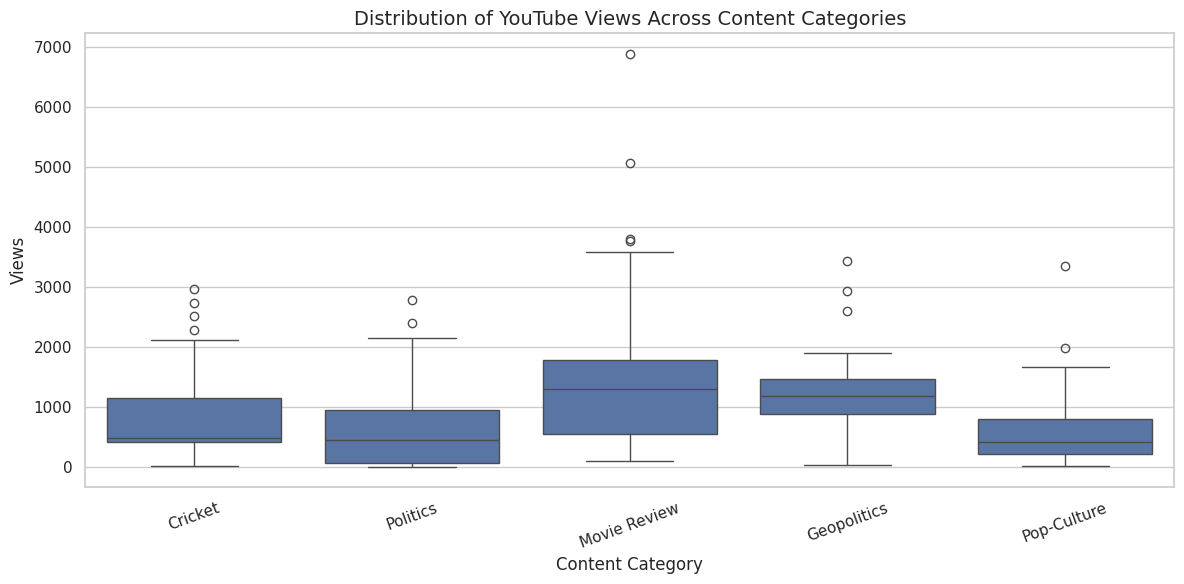

In [66]:

# Category-Wise Views Distribution

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=videos,
    x="category",
    y="views",
    showfliers=True
)

plt.title(
    "Distribution of YouTube Views Across Content Categories",
    fontsize=14
)

plt.xlabel("Content Category")
plt.ylabel("Views")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


**Content Share vs View Share Analysis**

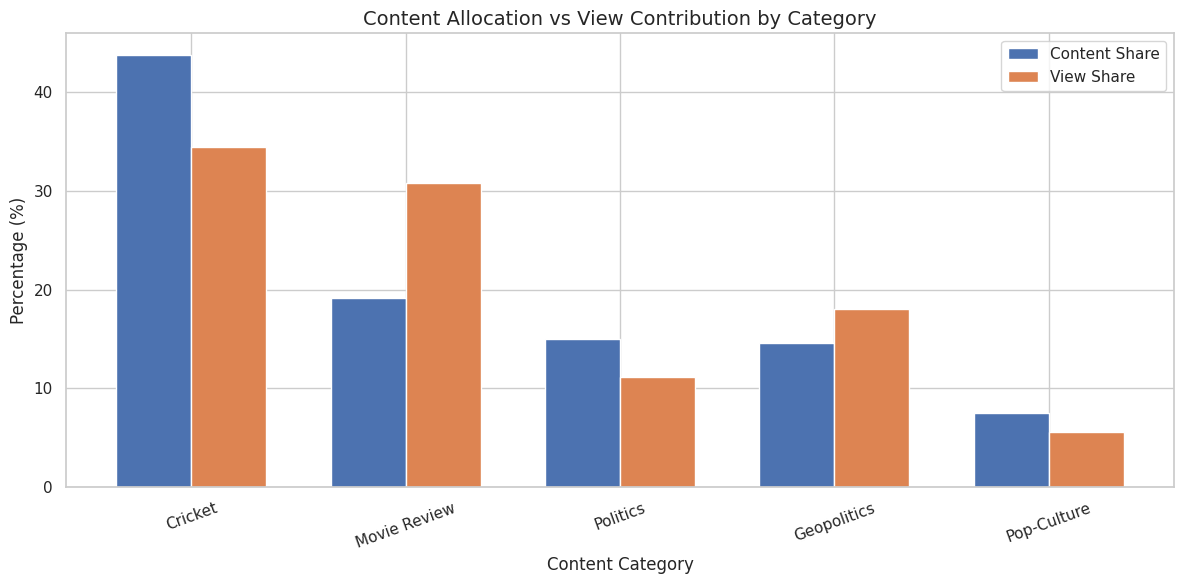

In [67]:

# Content Share vs View Share

# Prepare chart data
plot_data = category_portfolio.sort_values(
    by="content_share_pct",
    ascending=False
)

# Set chart dimensions
plt.figure(figsize=(12, 6))

x = np.arange(len(plot_data))
width = 0.35

# Content share bars
plt.bar(
    x - width / 2,
    plot_data["content_share_pct"],
    width,
    label="Content Share"
)

# View share bars
plt.bar(
    x + width / 2,
    plot_data["view_share_pct"],
    width,
    label="View Share"
)

# Chart formatting
plt.title(
    "Content Allocation vs View Contribution by Category",
    fontsize=14
)

plt.xlabel("Content Category")
plt.ylabel("Percentage (%)")

plt.xticks(
    x,
    plot_data["category"],
    rotation=20
)

plt.legend()
plt.tight_layout()
plt.show()


**Category-Wise Audience Engagement Visualization**

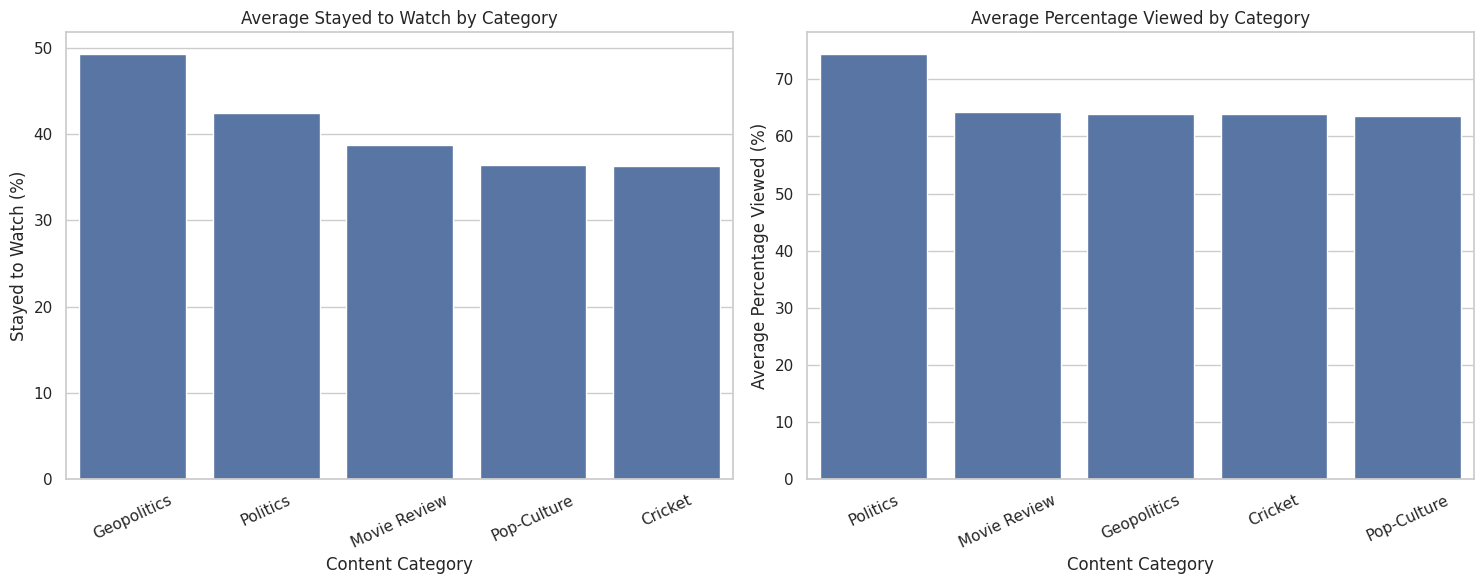

In [68]:

# Category Engagement Visualization

# Sort categories by stayed-to-watch performance
engagement_plot = category_engagement.sort_values(
    by="avg_stayed_to_watch_pct",
    ascending=False
)

# Create two separate charts
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Stayed to Watch
sns.barplot(
    data=engagement_plot,
    x="category",
    y="avg_stayed_to_watch_pct",
    ax=axes[0]
)

axes[0].set_title("Average Stayed to Watch by Category")
axes[0].set_xlabel("Content Category")
axes[0].set_ylabel("Stayed to Watch (%)")
axes[0].tick_params(axis="x", rotation=25)

# Chart 2: Average Percentage Viewed
viewed_plot = category_engagement.sort_values(
    by="avg_percentage_viewed_pct",
    ascending=False
)

sns.barplot(
    data=viewed_plot,
    x="category",
    y="avg_percentage_viewed_pct",
    ax=axes[1]
)

axes[1].set_title("Average Percentage Viewed by Category")
axes[1].set_xlabel("Content Category")
axes[1].set_ylabel("Average Percentage Viewed (%)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


**Video Duration vs Audience Performance**

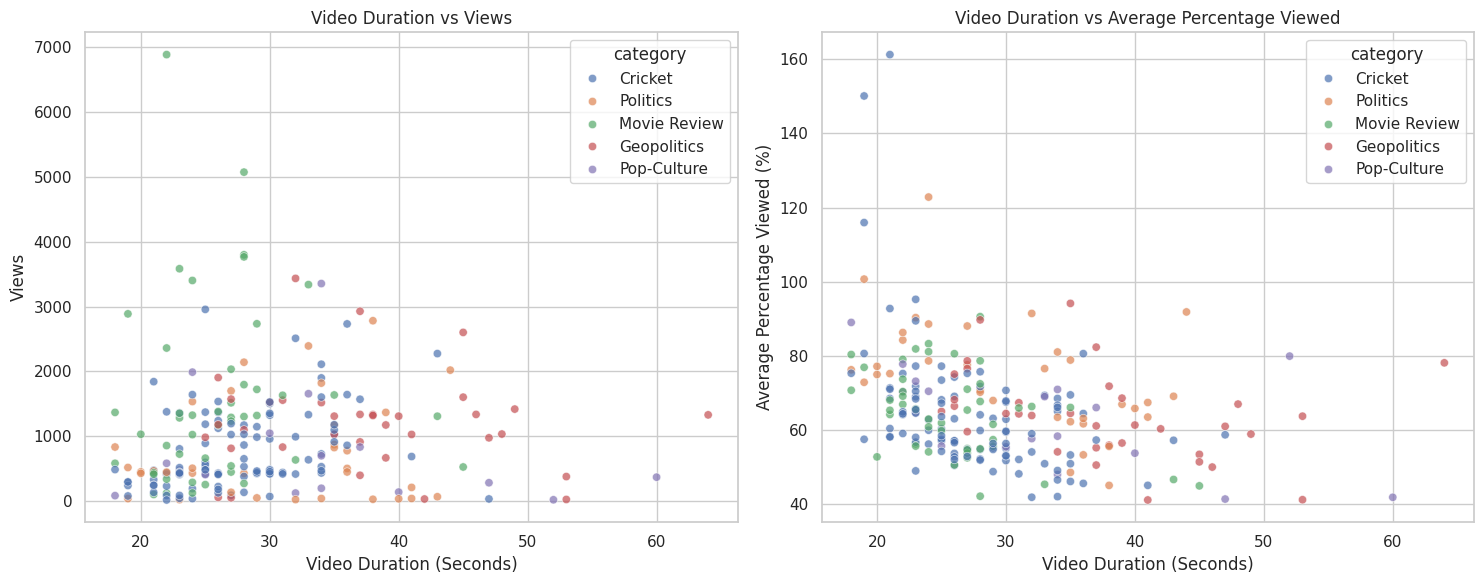

In [70]:

# Duration vs Performance Analysis

# Prepare data
duration_plot_data = videos[
    [
        "Duration",
        "views",
        "average_percentage_viewed_pct",
        "category"
    ]
].dropna()

# Create two scatter plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: Duration vs Views
sns.scatterplot(
    data=duration_plot_data,
    x="Duration",
    y="views",
    hue="category",
    alpha=0.7,
    ax=axes[0]
)

axes[0].set_title("Video Duration vs Views")
axes[0].set_xlabel("Video Duration (Seconds)")
axes[0].set_ylabel("Views")

# Chart 2: Duration vs Average Percentage Viewed
sns.scatterplot(
    data=duration_plot_data,
    x="Duration",
    y="average_percentage_viewed_pct",
    hue="category",
    alpha=0.7,
    ax=axes[1]
)

axes[1].set_title(
    "Video Duration vs Average Percentage Viewed"
)
axes[1].set_xlabel("Video Duration (Seconds)")
axes[1].set_ylabel("Average Percentage Viewed (%)")

plt.tight_layout()
plt.show()


**Statistical Hypothesis Testing**

In [71]:

# Kruskal-Wallis Statistical Test

# Prepare category-wise view groups
category_groups = []

for category in videos["category"].dropna().unique():

    group = videos.loc[
        videos["category"] == category,
        "views"
    ].dropna()

    if len(group) > 0:
        category_groups.append(group)

# Perform Kruskal-Wallis test
h_statistic, p_value = kruskal(*category_groups)

# Calculate sample size
total_sample_size = sum(len(group) for group in category_groups)
number_of_groups = len(category_groups)

# Calculate epsilon-squared effect size
epsilon_squared = (
    h_statistic - number_of_groups + 1
) / (total_sample_size - number_of_groups)

epsilon_squared = max(0, epsilon_squared)

# Display results
print("KRUSKAL-WALLIS TEST RESULTS")

print("H-Statistic:", round(h_statistic, 4))
print("P-Value:", f"{p_value:.8f}")
print("Epsilon-Squared:", round(epsilon_squared, 4))

print("\nHYPOTHESIS TESTING")

alpha = 0.05

if p_value < alpha:
    print("Reject Null Hypothesis.")
    print("Evidence of differences between category distributions.")
else:
    print("Fail to Reject Null Hypothesis.")
    print("Insufficient evidence of category distribution differences.")


KRUSKAL-WALLIS TEST RESULTS
H-Statistic: 26.0421
P-Value: 0.00003103
Epsilon-Squared: 0.0938

HYPOTHESIS TESTING
Reject Null Hypothesis.
Evidence of differences between category distributions.


**Post-Hoc Analysis**

In [73]:

# Dunn's Post-Hoc Test

# Install required package
%pip -q install scikit-posthocs

import scikit_posthocs as sp

# Run Dunn's test with Bonferroni correction
dunn_results = sp.posthoc_dunn(
    videos.dropna(subset=["category", "views"]),
    val_col="views",
    group_col="category",
    p_adjust="bonferroni"
)

print("DUNN'S POST-HOC TEST RESULTS:")
display(dunn_results.round(6))

# Extract category pairs
pairwise_results = []

for i, category_a in enumerate(dunn_results.index):

    for category_b in dunn_results.columns[i + 1:]:

        adjusted_p = dunn_results.loc[
            category_a, category_b
        ]

        pairwise_results.append({
            "Category A": category_a,
            "Category B": category_b,
            "Adjusted P-Value": adjusted_p,
            "Significant": adjusted_p < 0.05
        })

pairwise_table = pd.DataFrame(pairwise_results)

pairwise_table = pairwise_table.sort_values(
    by="Adjusted P-Value"
).reset_index(drop=True)

print("\nPAIRWISE CATEGORY COMPARISON:")
display(pairwise_table.round(6))


DUNN'S POST-HOC TEST RESULTS:


,Cricket,Geopolitics,Movie Review,Politics,Pop-Culture
Cricket,1.00,0.04,0.00,1.00,1.00
Geopolitics,0.04,1.00,1.00,0.02,0.06
Movie Review,0.00,1.00,1.00,0.00,0.02
Politics,1.00,0.02,0.00,1.00,1.00
Pop-Culture,1.00,0.06,0.02,1.00,1.00



PAIRWISE CATEGORY COMPARISON:


,Category A,Category B,Adjusted P-Value,Significant
0,Cricket,Movie Review,0.00,True
1,Movie Review,Politics,0.00,True
2,Movie Review,Pop-Culture,0.02,True
3,Geopolitics,Politics,0.02,True
4,Cricket,Geopolitics,0.04,True
5,Geopolitics,Pop-Culture,0.06,False
6,Cricket,Pop-Culture,1.00,False
7,Cricket,Politics,1.00,False
8,Geopolitics,Movie Review,1.00,False
9,Politics,Pop-Culture,1.00,False


**Content Context Analysis Flowchart**

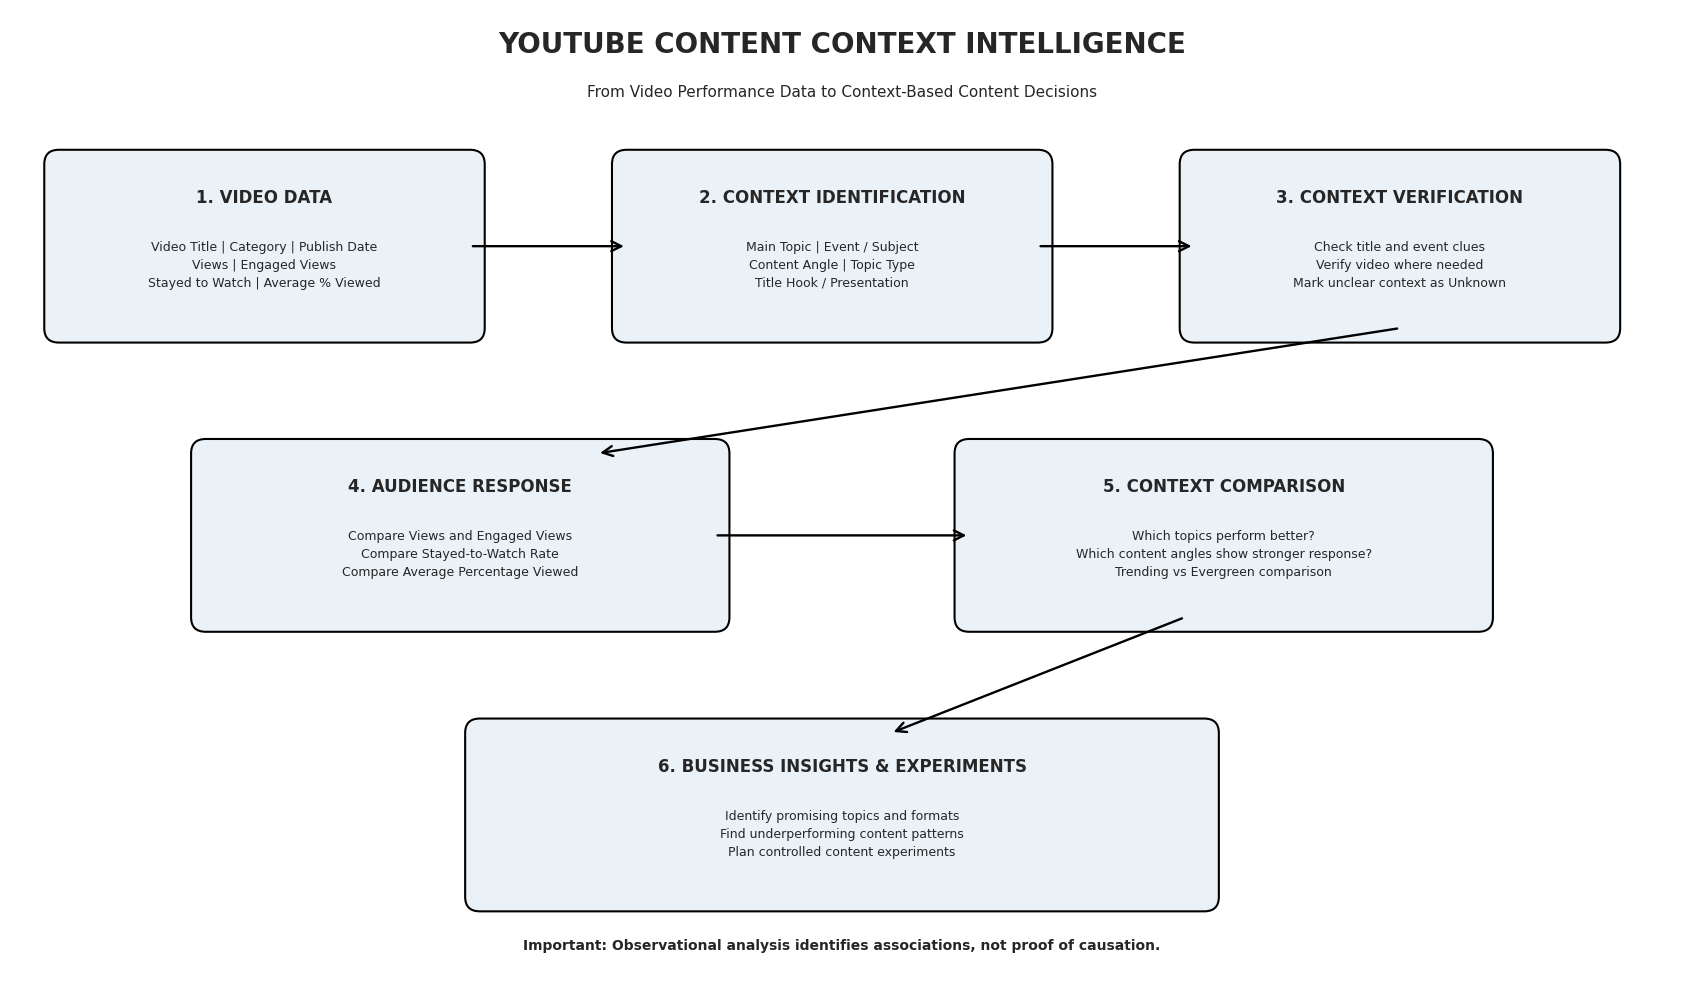

In [75]:

# Cell 30: Content Context Intelligence - Process Flowchart

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(17, 10))

ax.set_xlim(0, 17)
ax.set_ylim(0, 10)
ax.axis("off")

# Title
ax.text(
    8.5, 9.55,
    "YOUTUBE CONTENT CONTEXT INTELLIGENCE",
    ha="center",
    fontsize=20,
    fontweight="bold"
)

ax.text(
    8.5, 9.1,
    "From Video Performance Data to Context-Based Content Decisions",
    ha="center",
    fontsize=11
)

# Function to draw boxes
def draw_box(x, y, width, height, title, details):
    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.15",
        linewidth=1.5,
        edgecolor="black",
        facecolor="#EAF2F8"
    )
    ax.add_patch(box)

    ax.text(
        x + width/2,
        y + height - 0.35,
        title,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

    ax.text(
        x + width/2,
        y + height/2 - 0.2,
        details,
        ha="center",
        va="center",
        fontsize=9,
        linespacing=1.5
    )


# Stage 1: Source Data
draw_box(
    0.5, 6.7, 4.2, 1.7,
    "1. VIDEO DATA",
    "Video Title | Category | Publish Date\nViews | Engaged Views\nStayed to Watch | Average % Viewed"
)

# Stage 2: Context Identification
draw_box(
    6.3, 6.7, 4.2, 1.7,
    "2. CONTEXT IDENTIFICATION",
    "Main Topic | Event / Subject\nContent Angle | Topic Type\nTitle Hook / Presentation"
)

# Stage 3: Context Verification
draw_box(
    12.1, 6.7, 4.2, 1.7,
    "3. CONTEXT VERIFICATION",
    "Check title and event clues\nVerify video where needed\nMark unclear context as Unknown"
)

# Stage 4: Performance Analysis
draw_box(
    2.0, 3.7, 5.2, 1.7,
    "4. AUDIENCE RESPONSE",
    "Compare Views and Engaged Views\nCompare Stayed-to-Watch Rate\nCompare Average Percentage Viewed"
)

# Stage 5: Context Comparison
draw_box(
    9.8, 3.7, 5.2, 1.7,
    "5. CONTEXT COMPARISON",
    "Which topics perform better?\nWhich content angles show stronger response?\nTrending vs Evergreen comparison"
)

# Stage 6: Business Insights
draw_box(
    4.8, 0.8, 7.4, 1.7,
    "6. BUSINESS INSIGHTS & EXPERIMENTS",
    "Identify promising topics and formats\nFind underperforming content patterns\nPlan controlled content experiments"
)

# Arrows
arrows = [
    ((4.7, 7.55), (6.3, 7.55)),
    ((10.5, 7.55), (12.1, 7.55)),
    ((14.2, 6.7), (6.0, 5.4)),
    ((7.2, 4.55), (9.8, 4.55)),
    ((12.0, 3.7), (9.0, 2.5))
]

for start, end in arrows:
    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle="->",
        mutation_scale=18,
        linewidth=1.7,
        color="black",
        connectionstyle="arc3,rad=0.0"
    )
    ax.add_patch(arrow)

# Important analytical limitation
ax.text(
    8.5, 0.25,
    "Important: Observational analysis identifies associations, not proof of causation.",
    ha="center",
    fontsize=10,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**6. ACT**

**Final Business Recommendations & Executive Summary**

In [76]:
# 1. Identify key-performing categories

top_category = category_master.loc[
    category_master["median_views"].idxmax()
]

best_stayed_category = category_master.loc[
    category_master["avg_stayed_to_watch_pct"].idxmax()
]

best_viewed_category = category_master.loc[
    category_master["avg_percentage_viewed_pct"].idxmax()
]

most_consistent_category = category_master.loc[
    category_master["cv_pct"].idxmin()
]


# 2. Identify categories with positive and negative share gaps

positive_gap = category_portfolio[
    category_portfolio["share_gap_pp"] > 0
].sort_values(
    by="share_gap_pp",
    ascending=False
)

negative_gap = category_portfolio[
    category_portfolio["share_gap_pp"] < 0
].sort_values(
    by="share_gap_pp"
)


# 3. Statistical evidence

print("=" * 75)
print("YOUTUBE CONTENT PORTFOLIO INTELLIGENCE")
print("FINAL BUSINESS RECOMMENDATIONS")
print("=" * 75)

print("\n1. CATEGORY PERFORMANCE")

print(
    f"Highest Median Views: {top_category['category']} "
    f"({top_category['median_views']:,.0f} views)"
)

print(
    f"Best Stayed-to-Watch: {best_stayed_category['category']} "
    f"({best_stayed_category['avg_stayed_to_watch_pct']:.2f}%)"
)

print(
    f"Highest Average Percentage Viewed: "
    f"{best_viewed_category['category']} "
    f"({best_viewed_category['avg_percentage_viewed_pct']:.2f}%)"
)

print(
    f"Most Consistent Category: "
    f"{most_consistent_category['category']} "
    f"(CV: {most_consistent_category['cv_pct']:.2f}%)"
)


# 4. Content allocation opportunities

print("\n2. CONTENT ALLOCATION OPPORTUNITIES")

if not positive_gap.empty:
    print("\nCategories generating more view share than content share:")
    display(
        positive_gap[
            [
                "category",
                "content_share_pct",
                "view_share_pct",
                "share_gap_pp"
            ]
        ]
    )
else:
    print("No category has a positive share gap.")

if not negative_gap.empty:
    print("\nCategories generating less view share than content share:")
    display(
        negative_gap[
            [
                "category",
                "content_share_pct",
                "view_share_pct",
                "share_gap_pp"
            ]
        ]
    )
else:
    print("No category has a negative share gap.")


# 5. Statistical significance

print("\n3. STATISTICAL EVIDENCE")

print("Kruskal-Wallis H-Statistic:", round(h_statistic, 4))
print("P-Value:", f"{p_value:.8f}")
print("Effect Size (Epsilon-Squared):", round(epsilon_squared, 4))

if p_value < 0.05:
    print(
        "Interpretation: There is statistical evidence that "
        "view distributions differ across at least some categories."
    )
    print(
        "Use Dunn's post-hoc results to identify which category "
        "pairs show statistically significant differences."
    )
else:
    print(
        "Interpretation: The test did not find sufficient evidence "
        "of differences in category view distributions."
    )


# 6. Content context analysis status

print("\n4. CONTENT CONTEXT ANALYSIS")

context_columns = [
    "main_topic",
    "context_type",
    "content_angle",
    "topic_type",
    "title_hook_type"
]

if "context_review" in globals():

    available_context_columns = [
        col for col in context_columns
        if col in context_review.columns
    ]

    if available_context_columns:
        classified_rows = context_review[
            available_context_columns
        ].notna().any(axis=1).sum()

        total_context_rows = len(context_review)

        print("Videos with at least one context label:",
              classified_rows)

        print("Total videos in context review:",
              total_context_rows)

        if classified_rows == total_context_rows:
            print("Context review status: All videos have at least one label.")
        else:
            print("Context review status: Classification is incomplete.")
            print("Do not make final topic-level claims yet.")

    else:
        print("Context columns are not available.")

else:
    print("Context review dataset not found.")
    print("Complete Cell 30 context review before making context-based claims.")


# 7. Generate business recommendations

print("\n5. ACTIONABLE BUSINESS RECOMMENDATIONS")

print("""
A. CONTENT ALLOCATION
   Review categories where view share exceeds content share.
   Test whether additional videos can reproduce this performance.

B. UNDERPERFORMING PORTFOLIO
   Investigate categories where content share exceeds view share.
   Review topic selection, title packaging, audience relevance
   and video execution before reducing content volume.

C. AUDIENCE ATTENTION
   Study categories with stronger stayed-to-watch and
   average percentage viewed metrics.
   Views and attention should be evaluated separately.

D. PERFORMANCE CONSISTENCY
   Use the coefficient of variation to understand how volatile
   category-level views are. Do not judge consistency using
   average views alone.

E. VIDEO-LEVEL INVESTIGATION
   Review high-performing and low-performing videos within
   the same category to identify differences in topics,
   context, content angles and title hooks.

F. CONTROLLED EXPERIMENTS
   Test one major content change at a time, such as topic,
   hook or content angle. Track results across multiple videos.

G. DECISION LIMITATION
   These findings are observational. They do not prove that
   a category, topic or title caused higher performance.
   Production cost and creator time data are also unavailable,
   so financial ROI cannot be calculated.
""")


# 8. Final project status

print("\n6. PROJECT STATUS")

print("Category analysis: Completed")
print("Performance analysis: Completed")
print("Engagement analysis: Completed")
print("Statistical testing: Completed")
print("Business recommendations: Generated")

if "context_review" in globals():
    print("Context analysis: Requires verified labels before final conclusions.")
else:
    print("Context analysis: Pending.")

print("\n" + "=" * 75)
print("END OF YOUTUBE CONTENT PORTFOLIO INTELLIGENCE PROJECT")
print("=" * 75)


YOUTUBE CONTENT PORTFOLIO INTELLIGENCE
FINAL BUSINESS RECOMMENDATIONS

1. CATEGORY PERFORMANCE
Highest Median Views: Movie Review (1,298 views)
Best Stayed-to-Watch: Geopolitics (49.30%)
Highest Average Percentage Viewed: Politics (74.49%)
Most Consistent Category: Geopolitics (CV: 61.85%)

2. CONTENT ALLOCATION OPPORTUNITIES

Categories generating more view share than content share:


,category,content_share_pct,view_share_pct,share_gap_pp
1,Movie Review,19.17,30.80,11.63
3,Geopolitics,14.58,18.00,3.41



Categories generating less view share than content share:


,category,content_share_pct,view_share_pct,share_gap_pp
0,Cricket,43.75,34.45,-9.30
2,Politics,15.00,11.14,-3.86
4,Pop-Culture,7.50,5.62,-1.88



3. STATISTICAL EVIDENCE
Kruskal-Wallis H-Statistic: 26.0421
P-Value: 0.00003103
Effect Size (Epsilon-Squared): 0.0938
Interpretation: There is statistical evidence that view distributions differ across at least some categories.
Use Dunn's post-hoc results to identify which category pairs show statistically significant differences.

4. CONTENT CONTEXT ANALYSIS
Context review dataset not found.
Complete Cell 30 context review before making context-based claims.

5. ACTIONABLE BUSINESS RECOMMENDATIONS

A. CONTENT ALLOCATION
   Review categories where view share exceeds content share.
   Test whether additional videos can reproduce this performance.

B. UNDERPERFORMING PORTFOLIO
   Investigate categories where content share exceeds view share.
   Review topic selection, title packaging, audience relevance
   and video execution before reducing content volume.

C. AUDIENCE ATTENTION
   Study categories with stronger stayed-to-watch and
   average percentage viewed metrics.
   Views and att